# Stochastic Interpolants：解析边缘、ODE/SDE 与可学习场

这个 notebook 用 5 个实验验证 Stochastic Interpolants 的 6 个核心结论。重点是验证论文提出的数学性质，而不是只展示模型能够生成数据。

| 编号 | 核心结论 | 对应实验 |
|---|---|---|
| 1 | 随机插值可以构造具有相同边缘分布的 ODE：$p_{X_t}=p_{Y_t^{\mathrm{ODE}}}$ | 实验 1 |
| 2 | ODE 与 SDE 可以具有相同的单时刻边缘分布 | 实验 1 |
| 3 | 相同边缘分布不意味着相同样本轨迹 | 实验 2 |
| 4 | $\gamma(t)$ 改变概率路径，$\varepsilon$ 改变采样动力学 | 实验 3 |
| 5 | 边缘速度与 Score 都可以通过条件期望的 MSE 回归学习 | 实验 4 |
| 6 | 非零扩散 SDE 具有由漂移误差控制的终点 KL 上界 | 实验 5 |

实验 1、3、5 使用解析高斯基准，实验 4 才训练神经网络。每组实验都会明确区分理论等式、有限步数误差、有限样本误差和网络拟合误差。

> 运行环境：`conda activate pytorch`。神经网络自动使用 CUDA；随机种子固定为 42。

## 0. 随机插值与解析高斯基准

设相互独立的随机变量

$$
X_0\sim\mathcal N(0,I_2),\qquad
X_1\sim\mathcal N(\mu,\sigma_1^2I_2),\qquad
Z\sim\mathcal N(0,I_2),
$$

并定义随机插值

$$
X_t=(1-t)X_0+tX_1+\gamma(t)Z,
\qquad \gamma(t)=a\sin(\pi t).
$$

它的边缘分布具有解析形式

$$
p_t=\mathcal N(m_t,v_tI_2),\qquad
m_t=t\mu,
$$

$$
v_t=(1-t)^2+t^2\sigma_1^2+a^2\sin^2(\pi t).
$$

因此

$$
\dot v_t=-2(1-t)+2t\sigma_1^2+a^2\pi\sin(2\pi t).
$$

满足连续性方程的边缘速度与 Score 为

$$
b(t,x)=\dot m_t+\frac{\dot v_t}{2v_t}(x-m_t),
\qquad
s(t,x)=\nabla_x\log p_t(x)=-\frac{x-m_t}{v_t}.
$$

In [1]:
from pathlib import Path
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

OUTPUT_DIR = Path("stochastic_interpolants_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

MU = np.array([2.0, -1.5])
SIGMA1 = 0.65
N_SAMPLES = 6_000
SDE_STEPS = 240
EPSILON = 0.35

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

PyTorch: 2.5.1
Device: cuda
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/stochastic_interpolants_outputs


In [2]:
def gaussian_fields(t, x, gamma_amplitude=0.0):
    mean = t*MU
    variance = ((1-t)**2+(t*SIGMA1)**2
                +(gamma_amplitude*np.sin(np.pi*t))**2)
    variance_derivative = (-2*(1-t)+2*t*SIGMA1**2
                           +gamma_amplitude**2*np.pi*np.sin(2*np.pi*t))
    velocity = MU+0.5*variance_derivative/variance*(x-mean)
    score = -(x-mean)/variance
    return velocity, score, mean, variance


def simulate_process(x0, gamma_amplitude=0.0, epsilon=0.0, steps=SDE_STEPS,
                     mode="sde", rng=None, drift_error=None,
                     snapshots=(0.25, 0.5, 0.75, 1.0)):
    rng = np.random.default_rng(SEED) if rng is None else rng
    x = x0.copy()
    dt = 1.0/steps
    records = {0.0: x.copy()}
    snapshot_steps = {round(q*steps): q for q in snapshots}
    for step in range(steps):
        t = step*dt
        velocity, score, _, _ = gaussian_fields(t, x, gamma_amplitude)
        if drift_error is not None:
            velocity = velocity+drift_error(t, x)
        if mode == "ode":
            predictor = x+dt*velocity
            velocity_next, _, _, _ = gaussian_fields(t+dt, predictor, gamma_amplitude)
            if drift_error is not None:
                velocity_next = velocity_next+drift_error(t+dt, predictor)
            x = x+0.5*dt*(velocity+velocity_next)
        elif mode == "sde":
            noise = rng.standard_normal(x.shape)
            x = x+dt*(velocity+epsilon*score)+np.sqrt(2*epsilon*dt)*noise
        else:
            raise ValueError("mode must be 'ode' or 'sde'")
        if step+1 in snapshot_steps:
            records[snapshot_steps[step+1]] = x.copy()
    return records


def analytic_samples(t, n=N_SAMPLES, gamma_amplitude=0.0, rng=None):
    rng = np.random.default_rng(SEED) if rng is None else rng
    _, _, mean, variance = gaussian_fields(t, np.zeros((1, 2)), gamma_amplitude)
    return mean+np.sqrt(variance)*rng.standard_normal((n, 2))


def gaussian_kl(mean_p, covariance_p, mean_q, covariance_q):
    dimension = len(mean_p)
    return 0.5*(
        np.trace(np.linalg.solve(covariance_q, covariance_p))
        +(mean_q-mean_p)@np.linalg.solve(covariance_q, mean_q-mean_p)
        -dimension+np.linalg.slogdet(covariance_q)[1]-np.linalg.slogdet(covariance_p)[1]
    )


def moment_kl_to_analytic(samples, t=1.0, gamma_amplitude=0.0):
    _, _, target_mean, target_variance = gaussian_fields(
        t, np.zeros((1, 2)), gamma_amplitude
    )
    return gaussian_kl(
        samples.mean(0), np.cov(samples, rowvar=False),
        target_mean, target_variance*np.eye(2),
    )


def scatter(ax, samples, title, limit=4.5):
    ax.scatter(samples[:, 0], samples[:, 1], s=2, alpha=0.22, edgecolors="none")
    ax.set(title=title, xlim=(-limit, limit), ylim=(-limit, limit))
    ax.set_aspect("equal")
    ax.grid(alpha=0.12)

## 实验 1：随机插值、ODE 与 SDE 的边缘分布一致性

考虑概率流 ODE

$$
dY_t=b(t,Y_t)\,dt,
$$

以及带任意常数扩散强度 $\varepsilon\ge 0$ 的 SDE

$$
dY_t=\left[b(t,Y_t)+\varepsilon s(t,Y_t)\right]dt
+\sqrt{2\varepsilon}\,dW_t.
$$

由于 $\nabla\cdot(p_ts_t)=\Delta p_t$，SDE 的 Fokker–Planck 方程中 Score 漂移和扩散项抵消，剩下与 ODE 相同的

$$
\partial_t p_t=-\nabla\cdot(p_tb_t).
$$

论文结论是

$$
\boxed{p_{X_t}=p_{Y_t^{\mathrm{ODE}}}=p_{Y_t^{\mathrm{SDE}}}}.
$$

下面在 $t=0.25,0.5,0.75,1$ 比较解析随机插值、Heun ODE 和 Euler–Maruyama SDE。验证成功的标准是三排密度形状基本重合，ODE/SDE 的均值和协方差误差较小；有限样本和有限步积分使数值结果只会近似一致。

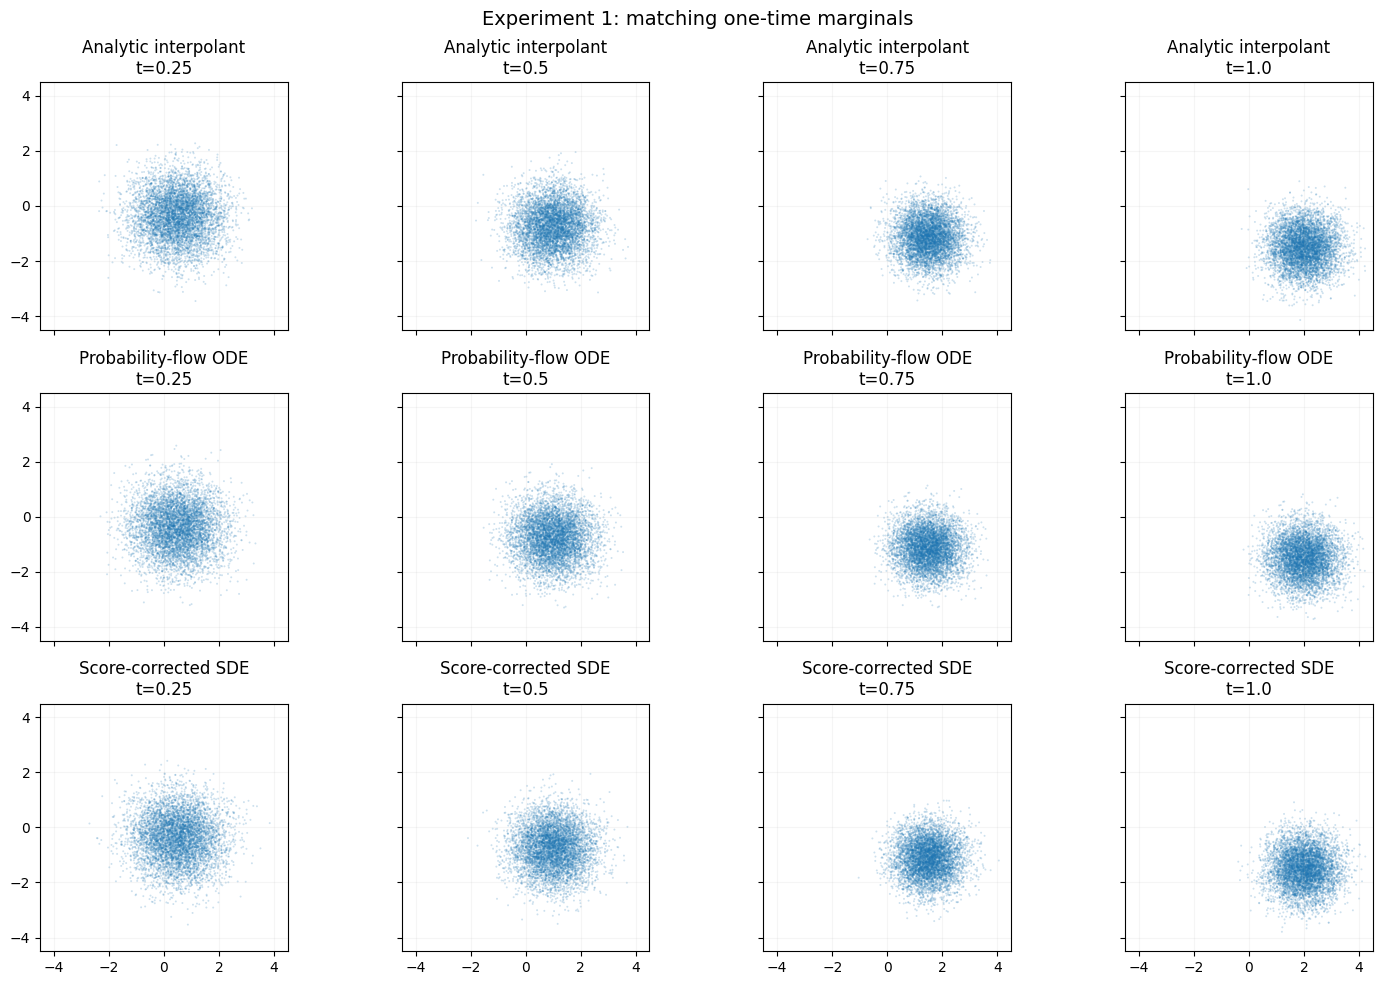

    t  process     mean error    covariance error
 0.25      ODE        0.01517             0.03813
 0.25      SDE        0.00767             0.04215
 0.50      ODE        0.01364             0.03083
 0.50      SDE        0.00609             0.01452
 0.75      ODE        0.01157             0.02218
 0.75      SDE        0.00639             0.00694
 1.00      ODE        0.01187             0.02334
 1.00      SDE        0.00972             0.00504


In [3]:
gamma_amplitude = 0.45
base_rng = np.random.default_rng(SEED+1)
x0 = base_rng.standard_normal((N_SAMPLES, 2))
ode_records = simulate_process(x0, gamma_amplitude=gamma_amplitude, mode="ode")
sde_records = simulate_process(
    x0, gamma_amplitude=gamma_amplitude, epsilon=EPSILON, mode="sde",
    rng=np.random.default_rng(SEED+2),
)
times = [0.25, 0.5, 0.75, 1.0]
marginal_metrics = []

fig, axes = plt.subplots(3, 4, figsize=(15, 10), sharex=True, sharey=True)
for column, t_value in enumerate(times):
    analytic = analytic_samples(
        t_value, gamma_amplitude=gamma_amplitude,
        rng=np.random.default_rng(SEED+10+column),
    )
    for row, (name, samples) in enumerate([
        ("Analytic interpolant", analytic),
        ("Probability-flow ODE", ode_records[t_value]),
        ("Score-corrected SDE", sde_records[t_value]),
    ]):
        scatter(axes[row, column], samples, f"{name}\nt={t_value}")

    _, _, mean, variance = gaussian_fields(t_value, analytic, gamma_amplitude)
    for name, samples in [("ODE", ode_records[t_value]), ("SDE", sde_records[t_value])]:
        mean_error = np.linalg.norm(samples.mean(0)-mean)
        covariance_error = np.linalg.norm(np.cov(samples, rowvar=False)-variance*np.eye(2))
        marginal_metrics.append((t_value, name, mean_error, covariance_error))

fig.suptitle("Experiment 1: matching one-time marginals", fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"01_marginal_consistency.png", dpi=170, bbox_inches="tight")
plt.show()

print(f"{'t':>5} {'process':>8} {'mean error':>14} {'covariance error':>19}")
for row in marginal_metrics:
    print(f"{row[0]:5.2f} {row[1]:>8} {row[2]:14.5f} {row[3]:19.5f}")

## 实验 2：相同边缘分布不等于相同样本路径

这个实验同时画出三种过程：

- **随机线性插值**：每次独立抽取终点 $X_1$，单条轨迹是从固定 $X_0$ 到 $X_1$ 的直线；
- **ODE**：轨迹由边缘速度和初值唯一确定，是一条确定性光滑曲线；
- **SDE**：Score 修正保证总体边缘不变，但布朗增量让单条轨迹产生随机波动。

一般有

$$
X_t\ne Y_t^{\mathrm{ODE}}\ne Y_t^{\mathrm{SDE}},
$$

同时仍可满足

$$
p_{X_t}=p_{Y_t^{\mathrm{ODE}}}=p_{Y_t^{\mathrm{SDE}}}.
$$

这说明概率分布演化相同，并不要求粒子运动轨迹相同。

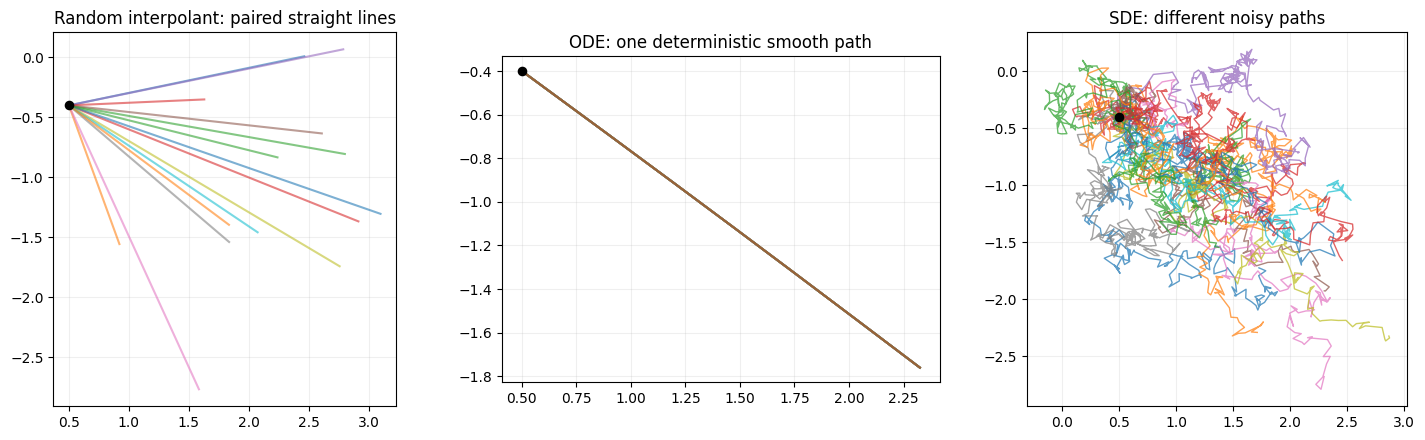

ODE endpoint spread: [4.44089210e-16 2.22044605e-16]
SDE endpoint spread: [0.47642148 0.55366987]


In [4]:
def repeated_paths(initial, epsilon=EPSILON, gamma_amplitude=0.0, steps=SDE_STEPS):
    dt = 1.0/steps
    ode_state = initial.copy()
    sde_state = initial.copy()
    ode_path = [ode_state.copy()]
    sde_path = [sde_state.copy()]
    rng = np.random.default_rng(SEED+20)
    for step in range(steps):
        t = step*dt
        velocity, _, _, _ = gaussian_fields(t, ode_state, gamma_amplitude)
        predictor = ode_state+dt*velocity
        velocity_next, _, _, _ = gaussian_fields(t+dt, predictor, gamma_amplitude)
        ode_state = ode_state+0.5*dt*(velocity+velocity_next)

        velocity, score, _, _ = gaussian_fields(t, sde_state, gamma_amplitude)
        sde_state = (sde_state+dt*(velocity+epsilon*score)
                     +np.sqrt(2*epsilon*dt)*rng.standard_normal(sde_state.shape))
        ode_path.append(ode_state.copy())
        sde_path.append(sde_state.copy())
    return np.asarray(ode_path), np.asarray(sde_path)


repetitions = 14
same_initial = np.tile(np.array([[0.5, -0.4]]), (repetitions, 1))
ode_path, sde_path = repeated_paths(same_initial)

# 对相同起点独立抽取高斯终点；gamma=0 时每条随机插值轨迹都是直线。
path_rng = np.random.default_rng(SEED+21)
random_endpoints = MU+SIGMA1*path_rng.standard_normal((repetitions, 2))
path_times = np.linspace(0, 1, SDE_STEPS+1)
interpolant_path = ((1-path_times[:, None, None])*same_initial[None, :, :]
                    +path_times[:, None, None]*random_endpoints[None, :, :])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for particle in range(repetitions):
    axes[0].plot(interpolant_path[:, particle, 0], interpolant_path[:, particle, 1], alpha=0.58)
    axes[1].plot(ode_path[:, particle, 0], ode_path[:, particle, 1], alpha=0.45)
    axes[2].plot(sde_path[:, particle, 0], sde_path[:, particle, 1], alpha=0.72, lw=1)
axes[0].set_title("Random interpolant: paired straight lines")
axes[1].set_title("ODE: one deterministic smooth path")
axes[2].set_title("SDE: different noisy paths")
for ax in axes:
    ax.scatter(*same_initial[0], c="black", s=35, zorder=5)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"02_ode_sde_paths.png", dpi=170, bbox_inches="tight")
plt.show()
print("ODE endpoint spread:", np.std(ode_path[-1], axis=0))
print("SDE endpoint spread:", np.std(sde_path[-1], axis=0))

## 实验 3：$\gamma$ 与 $\varepsilon$ 的作用不同

- $\gamma(t)$ 是随机插值定义的一部分。改变其幅度 $a$ 会直接改变中间方差 $v_t$，但因为 $\gamma(0)=\gamma(1)=0$，两个端点分布保持不变。这里使用光滑的 $a\sin(\pi t)$；常见的 $\lambda\sqrt{2t(1-t)}$ 具有相同的端点性质和实验结论。
- $\varepsilon$ 出现在 SDE 的扩散系数和 Score 修正项中。解析条件下它不改变 $p_t$，但会改变单条路径的随机程度；有限步 Euler–Maruyama 的误差通常随 $\varepsilon$ 增大，需要更小步长。

右图分别使用 60、180、540 步，展示随步数增加，Euler–Maruyama 离散过程的终点 KL 如何下降。由于本例的漂移是线性的，离散过程仍为高斯，可以递推其均值和方差并精确计算 KL，无需引入 Monte Carlo 采样噪声。

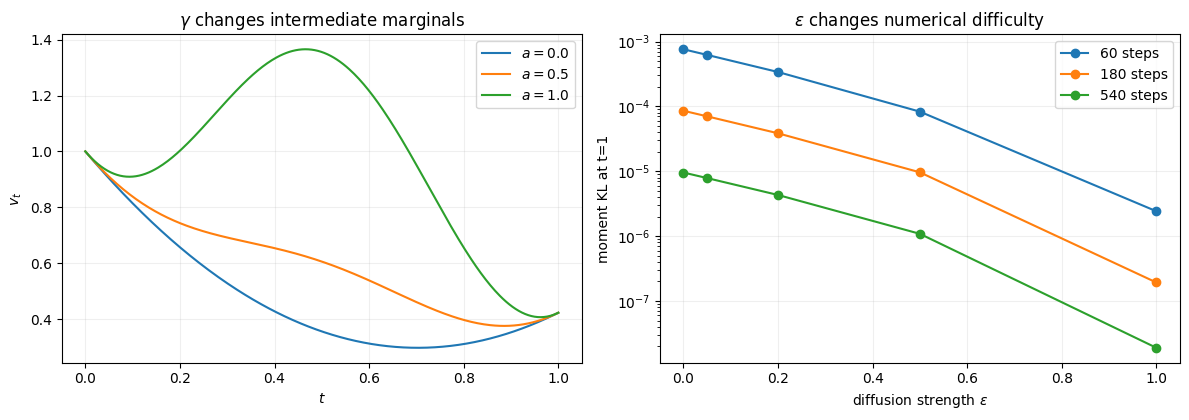

 60 steps: {0.0: np.float64(0.00076), 0.05: np.float64(0.000623), 0.2: np.float64(0.000339), 0.5: np.float64(8.3e-05), 1.0: np.float64(2e-06)}
180 steps: {0.0: np.float64(8.6e-05), 0.05: np.float64(7e-05), 0.2: np.float64(3.9e-05), 0.5: np.float64(1e-05), 1.0: np.float64(0.0)}
540 steps: {0.0: np.float64(1e-05), 0.05: np.float64(8e-06), 0.2: np.float64(4e-06), 0.5: np.float64(1e-06), 1.0: np.float64(0.0)}


In [5]:
time_grid = np.linspace(0, 1, 300)
gamma_values = [0.0, 0.5, 1.0]
epsilon_values = [0.0, 0.05, 0.2, 0.5, 1.0]
step_values = [60, 180, 540]


def discrete_process_kl(epsilon, steps, gamma_amplitude=0.45):
    # 对 Euler / Euler–Maruyama 离散格式精确递推均值和各向同性方差。
    dt = 1.0/steps
    mean = np.zeros(2)
    variance = 1.0
    for step in range(steps):
        t = step*dt
        _, _, target_mean, target_variance = gaussian_fields(
            t, np.zeros((1, 2)), gamma_amplitude
        )
        variance_derivative = (-2*(1-t)+2*t*SIGMA1**2
                               +gamma_amplitude**2*np.pi*np.sin(2*np.pi*t))
        coefficient = variance_derivative/(2*target_variance)-epsilon/target_variance
        multiplier = 1+dt*coefficient
        mean = mean+dt*(MU+coefficient*(mean-target_mean))
        variance = multiplier**2*variance+2*epsilon*dt
    return gaussian_kl(
        mean, variance*np.eye(2),
        MU, SIGMA1**2*np.eye(2),
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for amplitude in gamma_values:
    variances = [gaussian_fields(t, np.zeros((1, 2)), amplitude)[3] for t in time_grid]
    axes[0].plot(time_grid, variances, label=rf"$a={amplitude}$")
axes[0].set(xlabel="$t$", ylabel=r"$v_t$", title=r"$\gamma$ changes intermediate marginals")
axes[0].legend()

epsilon_errors = {}
for steps in step_values:
    errors = [discrete_process_kl(epsilon, steps) for epsilon in epsilon_values]
    epsilon_errors[steps] = errors
    axes[1].semilogy(epsilon_values, errors, "o-", label=f"{steps} steps")
axes[1].set(xlabel=r"diffusion strength $\varepsilon$", ylabel="moment KL at t=1",
            title=r"$\varepsilon$ changes numerical difficulty")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"03_gamma_vs_epsilon.png", dpi=170, bbox_inches="tight")
plt.show()

for steps, errors in epsilon_errors.items():
    print(f"{steps:3d} steps:", dict(zip(epsilon_values, np.round(errors, 6))))

## 实验 4：同时学习边缘速度与 Score

目标分布改为圆周上的八模态高斯混合。令

$$
X_t=(1-t)X_0+tX_1+\gamma(t)Z,
\qquad \gamma(t)=a\sin(\pi t).
$$

插值的条件速度为

$$
\dot X_t=X_1-X_0+a\pi\cos(\pi t)Z.
$$

网络的前两维用 MSE 回归 $\dot X_t$，其最优解是边缘速度 $b(t,x)$；后两维回归 $Z$，最优解 $\eta(t,x)=\mathbb E[Z\mid X_t=x]$ 满足

$$
s(t,x)=-\frac{\eta(t,x)}{\gamma(t)},\qquad 0<t<1.
$$

由于每个混合分量在时刻 $t$ 仍是高斯，可以解析计算真实边缘速度与 Score，从而直接验收网络，而不只观察 noisy training loss。

训练 loss 不应被要求趋近于零：同一个 $X_t=x$ 可能对应不同端点和噪声，监督标签存在不可约的条件方差。验证成功的标准是网络接近条件均值，即解析边缘速度/Score 误差较小、矢量场形状一致，并明显优于零预测基线。实验还按时间分箱绘制两种场的 MSE；由于 $s_\theta=-\eta_\theta/\gamma(t)$，当 $\gamma(t)$ 靠近零时，有限的噪声预测误差会被放大。

In [6]:
NUM_MODES = 8
RADIUS = 3.2
MODE_STD = 0.28
TRAIN_GAMMA = 0.35
TRAIN_STEPS = 5_000
TRAIN_BATCH = 1_024

angles = torch.arange(NUM_MODES, device=DEVICE)*2*math.pi/NUM_MODES
MIXTURE_CENTERS = RADIUS*torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)


def training_batch(n):
    t = 0.02+0.96*torch.rand(n, 1, device=DEVICE)
    x0 = torch.randn(n, 2, device=DEVICE)
    labels = torch.randint(NUM_MODES, (n,), device=DEVICE)
    x1 = MIXTURE_CENTERS[labels]+MODE_STD*torch.randn(n, 2, device=DEVICE)
    z = torch.randn(n, 2, device=DEVICE)
    gamma = TRAIN_GAMMA*torch.sin(torch.pi*t)
    x = (1-t)*x0+t*x1+gamma*z
    conditional_velocity = x1-x0+TRAIN_GAMMA*torch.pi*torch.cos(torch.pi*t)*z
    return t, x, conditional_velocity, z


def exact_mixture_fields(t, x):
    means = t[:, None, :]*MIXTURE_CENTERS[None, :, :]
    gamma = TRAIN_GAMMA*torch.sin(torch.pi*t)
    gamma_derivative = TRAIN_GAMMA*torch.pi*torch.cos(torch.pi*t)
    variance = (1-t).square()+(t*MODE_STD).square()+gamma.square()
    delta = x[:, None, :]-means
    logits = -delta.square().sum(-1)/(2*variance)
    responsibilities = torch.softmax(logits, dim=1)

    component_score = -delta/variance[:, None, :]
    score = (responsibilities[:, :, None]*component_score).sum(dim=1)

    velocity_covariance = t*MODE_STD**2-(1-t)+gamma*gamma_derivative
    component_velocity = (MIXTURE_CENTERS[None, :, :]
                          +(velocity_covariance/variance)[:, None, :]*delta)
    velocity = (responsibilities[:, :, None]*component_velocity).sum(dim=1)
    return velocity, score


class JointFieldNet(nn.Module):
    def __init__(self, hidden=128, frequencies=4):
        super().__init__()
        self.frequencies = frequencies
        time_dim = 1+2*frequencies
        self.net = nn.Sequential(
            nn.Linear(2+time_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 4),
        )

    def time_embedding(self, t):
        frequency = torch.arange(1, self.frequencies+1, device=t.device, dtype=t.dtype)[None, :]
        phase = torch.pi*t*frequency
        return torch.cat([t, torch.sin(phase), torch.cos(phase)], dim=1)

    def forward(self, t, x):
        return self.net(torch.cat([x, self.time_embedding(t)], dim=1))


model = JointFieldNet().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1.5e-3)
losses = []
training_started = time.perf_counter()
model.train()
for step in range(1, TRAIN_STEPS+1):
    t, x, conditional_velocity, z = training_batch(TRAIN_BATCH)
    prediction = model(t, x)
    velocity_loss = F.mse_loss(prediction[:, :2], conditional_velocity)
    noise_loss = F.mse_loss(prediction[:, 2:], z)
    loss = velocity_loss+noise_loss
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if step == 1 or step % 500 == 0:
        print(f"step {step:4d}/{TRAIN_STEPS}: joint loss(100-step avg)={np.mean(losses[-100:]):.6f}")

model.eval()
print(f"Training finished in {time.perf_counter()-training_started:.1f} s")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")
torch.save(model.state_dict(), OUTPUT_DIR/"joint_velocity_score_net.pt")

step    1/5000: joint loss(100-step avg)=7.834997


step  500/5000: joint loss(100-step avg)=4.700661


step 1000/5000: joint loss(100-step avg)=4.580927


step 1500/5000: joint loss(100-step avg)=4.557872


step 2000/5000: joint loss(100-step avg)=4.566179


...

step 3000/5000: joint loss(100-step avg)=4.535880


step 3500/5000: joint loss(100-step avg)=4.551911


step 4000/5000: joint loss(100-step avg)=4.562296


step 4500/5000: joint loss(100-step avg)=4.558689


step 5000/5000: joint loss(100-step avg)=4.569230
Training finished in 14.2 s
Trainable parameters: 35,076


conditional velocity target MSE        : 3.740449
velocity zero baseline MSE             : 6.829857
exact marginal velocity MSE            : 0.019378
noise target MSE                       : 0.869165
noise zero baseline MSE                : 0.997219
analytic score MSE (middle t)          : 0.061523


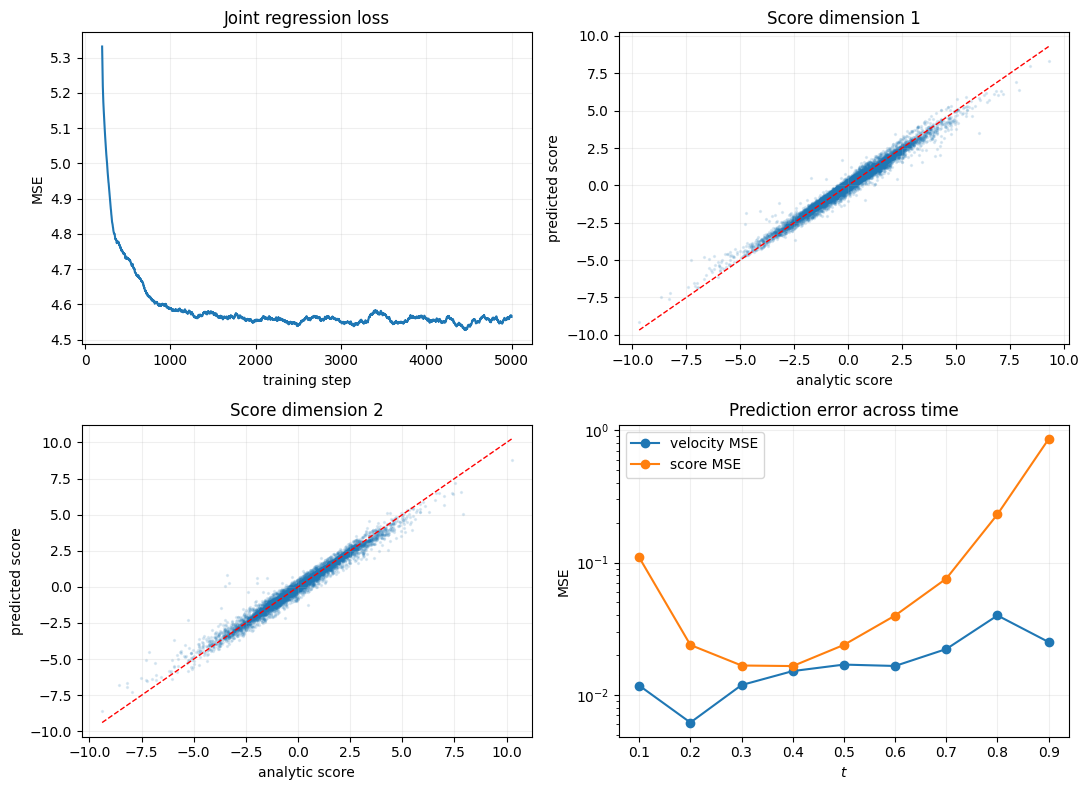

In [7]:
@torch.no_grad()
def evaluate_joint_model(n=16_000):
    t, x, conditional_velocity, z = training_batch(n)
    prediction = model(t, x)
    exact_velocity, exact_score = exact_mixture_fields(t, x)
    gamma = TRAIN_GAMMA*torch.sin(torch.pi*t)
    predicted_score = -prediction[:, 2:]/gamma
    middle = (t[:, 0] > 0.15) & (t[:, 0] < 0.85)
    metrics = {
        "conditional velocity target MSE": F.mse_loss(prediction[:, :2], conditional_velocity).item(),
        "velocity zero baseline MSE": conditional_velocity.square().mean().item(),
        "exact marginal velocity MSE": F.mse_loss(prediction[:, :2], exact_velocity).item(),
        "noise target MSE": F.mse_loss(prediction[:, 2:], z).item(),
        "noise zero baseline MSE": z.square().mean().item(),
        "analytic score MSE (middle t)": F.mse_loss(predicted_score[middle], exact_score[middle]).item(),
    }
    details = {
        "t": t.cpu(),
        "exact_score": exact_score.cpu(),
        "predicted_score": predicted_score.cpu(),
        "velocity_error": (prediction[:, :2]-exact_velocity).square().mean(1).cpu(),
        "score_error": (predicted_score-exact_score).square().mean(1).cpu(),
        "middle": middle.cpu(),
    }
    return metrics, details


joint_metrics, evaluation = evaluate_joint_model()
for name, value in joint_metrics.items():
    print(f"{name:<39}: {value:.6f}")

window = 200
smooth_loss = np.convolve(losses, np.ones(window)/window, mode="valid")
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].plot(np.arange(window, len(losses)+1), smooth_loss)
axes[0, 0].set(title="Joint regression loss", xlabel="training step", ylabel="MSE")
middle = evaluation["middle"]
for dimension in range(2):
    ax = axes[0, 1] if dimension == 0 else axes[1, 0]
    exact_component = evaluation["exact_score"][middle, dimension]
    predicted_component = evaluation["predicted_score"][middle, dimension]
    ax.scatter(
        exact_component.numpy(), predicted_component.numpy(),
        s=2, alpha=0.12,
    )
    low = min(exact_component.min(), predicted_component.min()).item()
    high = max(exact_component.max(), predicted_component.max()).item()
    ax.plot([low, high], [low, high], "r--", lw=1)
    ax.set(title=f"Score dimension {dimension+1}",
           xlabel="analytic score", ylabel="predicted score")

time_centers = np.linspace(0.1, 0.9, 9)
velocity_by_time = []
score_by_time = []
t_flat = evaluation["t"][:, 0]
for center in time_centers:
    time_mask = (t_flat >= center-0.05) & (t_flat < center+0.05)
    velocity_by_time.append(evaluation["velocity_error"][time_mask].mean().item())
    score_by_time.append(evaluation["score_error"][time_mask].mean().item())
axes[1, 1].semilogy(time_centers, velocity_by_time, "o-", label="velocity MSE")
axes[1, 1].semilogy(time_centers, score_by_time, "o-", label="score MSE")
axes[1, 1].set(title="Prediction error across time", xlabel="$t$", ylabel="MSE")
axes[1, 1].legend()
for ax in axes.ravel():
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"04_training_and_score_regression.png", dpi=170, bbox_inches="tight")
plt.show()

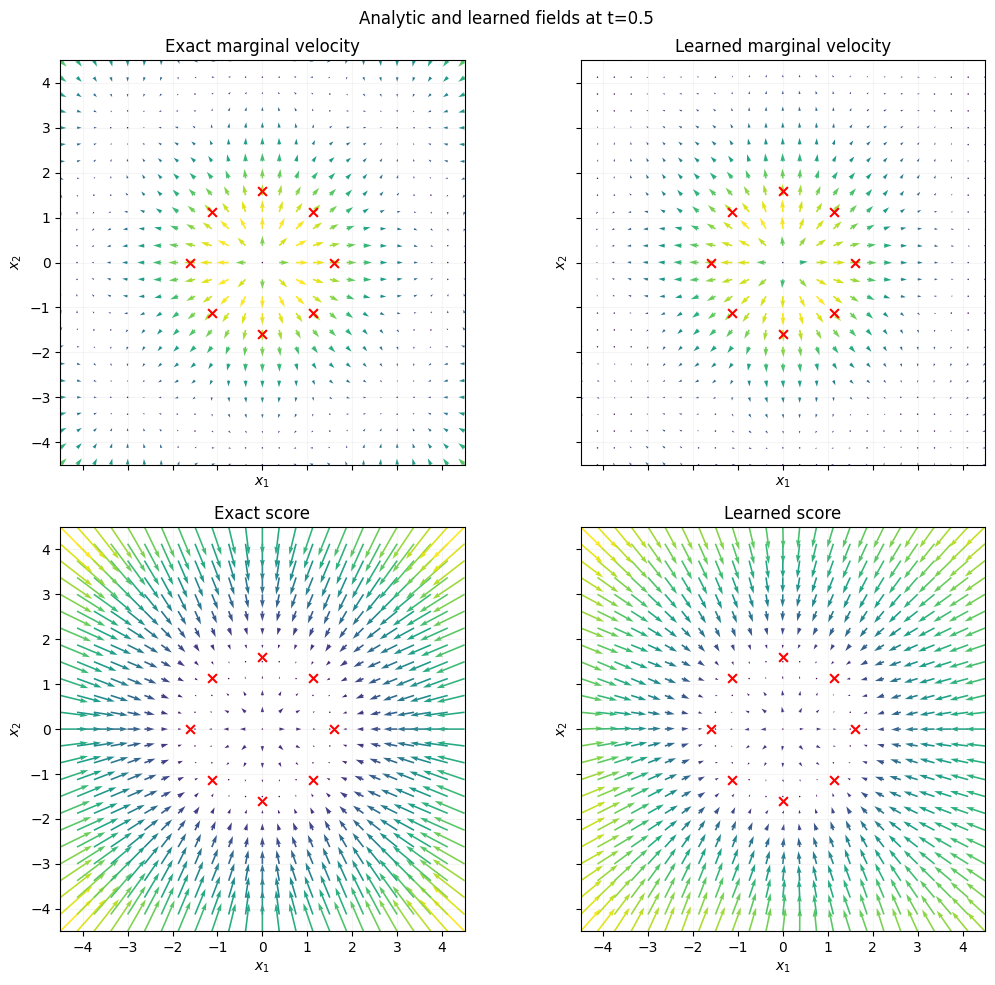

In [8]:
@torch.no_grad()
def plot_learned_fields(t_value=0.5):
    axis = torch.linspace(-4.5, 4.5, 25, device=DEVICE)
    yy, xx = torch.meshgrid(axis, axis, indexing="ij")
    points = torch.stack([xx.ravel(), yy.ravel()], dim=1)
    t = torch.full((len(points), 1), t_value, device=DEVICE)
    exact_velocity, exact_score = exact_mixture_fields(t, points)
    prediction = model(t, points)
    learned_velocity = prediction[:, :2]
    learned_score = -prediction[:, 2:]/(TRAIN_GAMMA*torch.sin(torch.pi*t))

    fields = [exact_velocity, learned_velocity, exact_score, learned_score]
    titles = ["Exact marginal velocity", "Learned marginal velocity",
              "Exact score", "Learned score"]
    points_np = points.cpu().numpy()
    current_centers = (t_value*MIXTURE_CENTERS).cpu().numpy()
    fig, axes = plt.subplots(2, 2, figsize=(11, 10), sharex=True, sharey=True)
    for ax, field, title in zip(axes.ravel(), fields, titles):
        field_np = field.cpu().numpy()
        magnitude = np.linalg.norm(field_np, axis=1)
        ax.quiver(points_np[:, 0], points_np[:, 1], field_np[:, 0], field_np[:, 1], magnitude,
                  cmap="viridis", angles="xy", scale_units="xy", scale=12, width=0.004)
        ax.scatter(current_centers[:, 0], current_centers[:, 1], c="red", marker="x", s=40)
        ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-4.5, 4.5), ylim=(-4.5, 4.5))
        ax.set_aspect("equal")
        ax.grid(alpha=0.12)
    fig.suptitle(f"Analytic and learned fields at t={t_value}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR/"05_exact_vs_learned_fields.png", dpi=170, bbox_inches="tight")
    plt.show()


plot_learned_fields()

## 实验 5：速度误差、Score 误差与 SDE KL 上界

真实 SDE 漂移与近似漂移分别为

$$
f=b+\varepsilon s,
\qquad
\widehat f=\widehat b+\varepsilon\widehat s.
$$

Girsanov 定理和数据处理不等式给出

$$
D_{\mathrm{KL}}(p_1\Vert\widehat p_1)
\le \frac{1}{4\varepsilon}
\int_0^1\mathbb E_{p_t}\|\widehat f-f\|^2dt,
\qquad \varepsilon>0.
$$

再令

$$
A=\int_0^1\mathbb E\|\widehat b-b\|^2dt,
\qquad
B=\int_0^1\mathbb E\|\widehat s-s\|^2dt,
$$

利用 $\|u+v\|^2\le 2\|u\|^2+2\|v\|^2$ 可得到便于解释的分离上界

$$
D_{\mathrm{KL}}(p_1\Vert\widehat p_1)
\le \frac{A}{2\varepsilon}+\frac{\varepsilon B}{2}.
$$

下面注入恒定且相互正交的误差

$$
\widehat b=b+\delta_b,
\qquad
\widehat s=s+\delta_s.
$$

此时 $A=\|\delta_b\|^2$、$B=\|\delta_s\|^2$，分离上界在

$$
\varepsilon^*=\sqrt{A/B}
$$

处取得最小值。由于整个系统保持线性高斯，可以用 RK4 精确求解均值与方差 ODE，再计算真正的终点高斯 KL。

验证成功要求所有扩散强度下实际 KL 均不超过上界。$\varepsilon^*$ 只最小化理论上界，真实 KL 的最小点不必与它一致；该结论也不适用于 $\varepsilon=0$ 的 ODE。

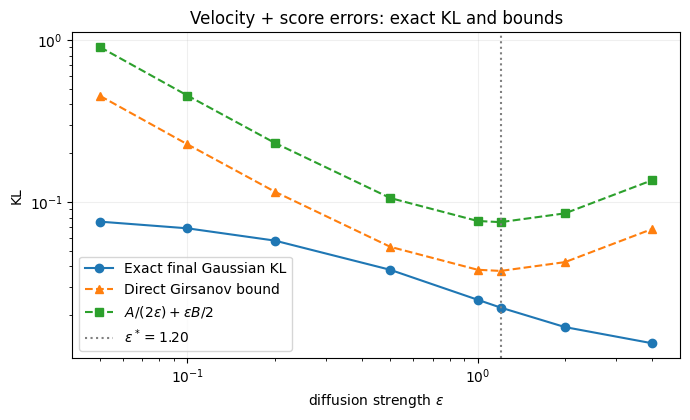

A=0.09000, B=0.06250, epsilon*=1.20000
  epsilon      exact KL    direct bound       A/B bound   verified
     0.05     0.0755198       0.4507812       0.9015625       True
     0.10     0.0687031       0.2265625       0.4531250       True
     0.20     0.0577029       0.1156250       0.2312500       True
     0.50     0.0380946       0.0528125       0.1056250       True
     1.00     0.0248975       0.0381250       0.0762500       True
     1.20     0.0222738       0.0375000       0.0750000       True
     2.00     0.0168816       0.0425000       0.0850000       True
     4.00     0.0134071       0.0681250       0.1362500       True


In [9]:
def exact_moment_kl(epsilon, bias, steps=2_000, gamma_amplitude=0.45):
    dt = 1.0/steps
    generated_mean = np.zeros(2)
    generated_variance = 1.0

    def rhs(t, current_mean, current_variance):
        _, _, target_mean, target_variance = gaussian_fields(
            t, np.zeros((1, 2)), gamma_amplitude
        )
        variance_derivative = (-2*(1-t)+2*t*SIGMA1**2
                               +gamma_amplitude**2*np.pi*np.sin(2*np.pi*t))
        linear_coefficient = variance_derivative/(2*target_variance)-epsilon/target_variance
        mean_derivative = MU+linear_coefficient*(current_mean-target_mean)+bias
        variance_ode = 2*linear_coefficient*current_variance+2*epsilon
        return mean_derivative, variance_ode

    for step in range(steps):
        t = step*dt
        k1_mean, k1_variance = rhs(t, generated_mean, generated_variance)
        k2_mean, k2_variance = rhs(
            t+dt/2, generated_mean+dt*k1_mean/2, generated_variance+dt*k1_variance/2
        )
        k3_mean, k3_variance = rhs(
            t+dt/2, generated_mean+dt*k2_mean/2, generated_variance+dt*k2_variance/2
        )
        k4_mean, k4_variance = rhs(
            t+dt, generated_mean+dt*k3_mean, generated_variance+dt*k3_variance
        )
        generated_mean += dt*(k1_mean+2*k2_mean+2*k3_mean+k4_mean)/6
        generated_variance += dt*(k1_variance+2*k2_variance+2*k3_variance+k4_variance)/6

    return gaussian_kl(
        MU, SIGMA1**2*np.eye(2),
        generated_mean, generated_variance*np.eye(2),
    )


velocity_bias = np.array([0.30, 0.0])
score_bias = np.array([0.0, 0.25])
A = np.sum(velocity_bias**2)
B = np.sum(score_bias**2)
optimal_epsilon = math.sqrt(A/B)
epsilon_grid = np.array([0.05, 0.1, 0.2, 0.5, 1.0, optimal_epsilon, 2.0, 4.0])

# 模型 SDE 的总漂移误差是 delta_b + epsilon * delta_s。
total_biases = [velocity_bias+epsilon*score_bias for epsilon in epsilon_grid]
actual_kl = np.array([
    exact_moment_kl(epsilon, total_bias)
    for epsilon, total_bias in zip(epsilon_grid, total_biases)
])
tight_girsanov_bound = np.array([
    np.sum(total_bias**2)/(4*epsilon)
    for epsilon, total_bias in zip(epsilon_grid, total_biases)
])
separated_bound = A/(2*epsilon_grid)+epsilon_grid*B/2

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.loglog(epsilon_grid, actual_kl, "o-", label="Exact final Gaussian KL")
ax.loglog(epsilon_grid, tight_girsanov_bound, "^--", label="Direct Girsanov bound")
ax.loglog(epsilon_grid, separated_bound, "s--", label=r"$A/(2\varepsilon)+\varepsilon B/2$")
ax.axvline(optimal_epsilon, color="gray", ls=":", label=rf"$\varepsilon^*={optimal_epsilon:.2f}$")
ax.set(xlabel=r"diffusion strength $\varepsilon$", ylabel="KL",
       title="Velocity + score errors: exact KL and bounds")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"06_sde_kl_bound.png", dpi=170, bbox_inches="tight")
plt.show()

print(f"A={A:.5f}, B={B:.5f}, epsilon*={optimal_epsilon:.5f}")
print(f"{'epsilon':>9} {'exact KL':>13} {'direct bound':>15} {'A/B bound':>15} {'verified':>10}")
for epsilon, exact, direct, separated in zip(
    epsilon_grid, actual_kl, tight_girsanov_bound, separated_bound
):
    verified = exact <= direct+1e-8 and direct <= separated+1e-8
    print(f"{epsilon:9.2f} {exact:13.7f} {direct:15.7f} {separated:15.7f} {str(verified):>10}")

## 实验结论

1. **边缘分布一致性**：解析速度和 Score 下，随机插值、概率流 ODE、Score 修正 SDE 共享同一组 $p_t$；有限步数和有限样本带来小的数值误差。这同时验证了核心结论 1 和 2。
2. **路径不等价**：随机插值使用随机配对直线；固定同一个初始点时 ODE 轨迹唯一，而 SDE 轨迹随布朗噪声变化。路径不同不影响总体边缘一致。
3. **两个参数作用不同**：$\gamma$ 定义概率路径并改变中间边缘；$\varepsilon$ 调节 SDE 随机性，理想情况下不改变边缘，但会改变数值求解难度。
4. **条件期望回归**：同一个网络可以从随机插值样本学习边缘速度和噪声条件均值；后者除以 $-\gamma(t)$ 后恢复 Score。解析八模态场提供了独立验收标准。
5. **误差控制的适用范围**：非零扩散下可以用速度与 Score 误差控制路径 KL 和终点 KL。分离上界关于 $\varepsilon$ 呈 U 形，但其最优点不必是真实 KL 的最优点；该结论不能直接延伸到零扩散 ODE。

### 覆盖范围与尚未验证的内容

| 论文方向 | 当前覆盖情况 | 后续需要 |
|---|---|---|
| One-sided Interpolant 与 VP-SDE | 部分覆盖 | 另设单边插值并逐项匹配 VP 系数 |
| Schrödinger Bridge 最优性 | 未覆盖 | 实现路径空间控制或简单高斯 Schrödinger Bridge |
| Reflow 轨迹直线化 | 未覆盖 | 训练至少两轮模型并比较 Straightness |
| 似然估计与大型生成模型 | 未覆盖 | 数值散度、真实数据集和更大网络 |

若要继续覆盖论文后半部分，最合适的第六个实验是一维高斯 Schrödinger Bridge：比较普通插值与最优随机输运桥的概率路径和控制能量。它需要新的优化目标，因此没有混入当前五个基础理论实验。